In [1]:
import os
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

os.makedirs("figures", exist_ok=True)

titanic = pd.read_csv("../exercice8/data/titanic_propre.csv")
titanic["classe_fr"] = titanic["class"].map({"First": "1re classe", "Second": "2e classe", "Third": "3e classe"})
titanic["sexe_fr"] = titanic["sex"].map({"female": "Femmes", "male": "Hommes"})
ordre_classes = ["1re classe", "2e classe", "3e classe"]

taxis = sns.load_dataset("taxis")
taxis["pickup"] = pd.to_datetime(taxis["pickup"])

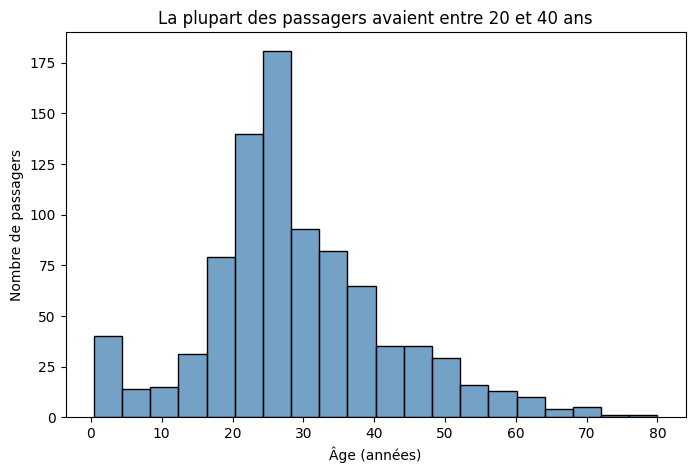

In [2]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.histplot(data=titanic, x="age", bins=20, color="steelblue", ax=ax)
ax.set_title("La plupart des passagers avaient entre 20 et 40 ans")
ax.set_xlabel("Âge (années)")
ax.set_ylabel("Nombre de passagers")
fig.savefig("figures/01_age.png", dpi=150, bbox_inches="tight")
plt.show()

**Type** : histogramme, car l'âge est une variable numérique et on veut voir comment elle se répartit.

**Conclusion** : la majorité des passagers avaient entre 20 et 40 ans, avec un pic autour de 25-30 ans. Il y avait aussi un petit groupe de jeunes enfants (0 à 5 ans) et très peu de personnes de plus de 60 ans.

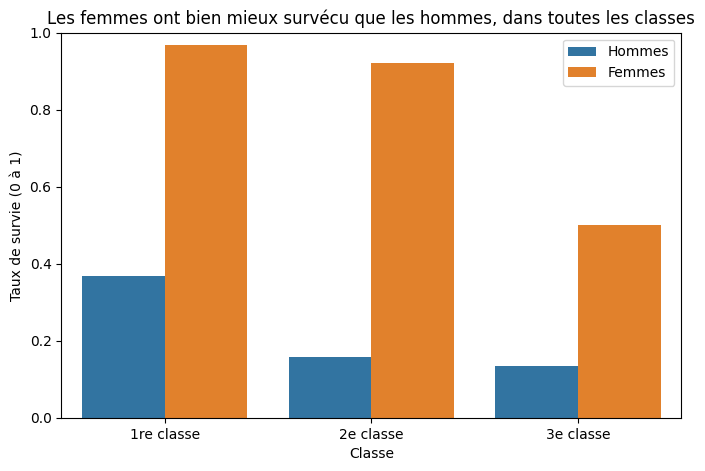

In [3]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(data=titanic, x="classe_fr", y="survived", hue="sexe_fr",
            order=ordre_classes, errorbar=None, ax=ax)
ax.set_title("Les femmes ont bien mieux survécu que les hommes, dans toutes les classes")
ax.set_xlabel("Classe")
ax.set_ylabel("Taux de survie (0 à 1)")
ax.set_ylim(0, 1)
ax.legend(title="")
fig.savefig("figures/02_survie_classe_sexe.png", dpi=150, bbox_inches="tight")
plt.show()

**Type** : barres groupées, car on compare une proportion (la survie) entre des catégories (classe et sexe).

**Conclusion** : dans chaque classe, les femmes ont un taux de survie bien supérieur à celui des hommes, et le taux baisse quand on passe de la 1re à la 3e classe.

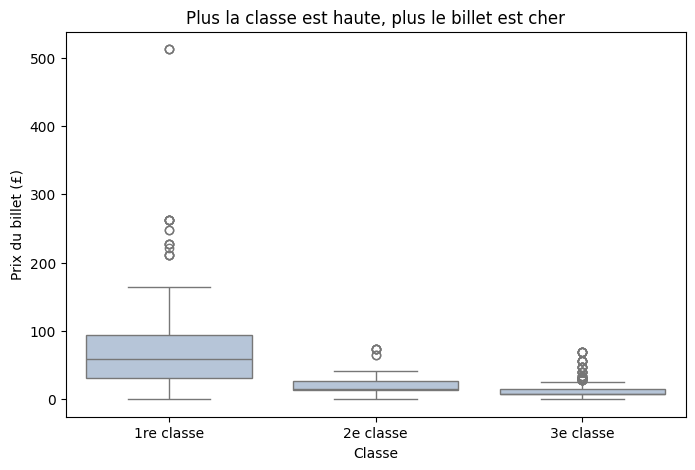

In [4]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.boxplot(data=titanic, x="classe_fr", y="fare", order=ordre_classes,
            color="lightsteelblue", ax=ax)
ax.set_title("Plus la classe est haute, plus le billet est cher")
ax.set_xlabel("Classe")
ax.set_ylabel("Prix du billet (£)")
fig.savefig("figures/03_prix_classe.png", dpi=150, bbox_inches="tight")
plt.show()

**Type** : boîte à moustaches, car elle compare la répartition d'une variable numérique (le prix) entre plusieurs catégories et montre les valeurs extrêmes.

**Conclusion** : le prix médian grimpe nettement de la 3e à la 1re classe, et la 1re classe a des écarts de prix très importants avec quelques billets très chers.

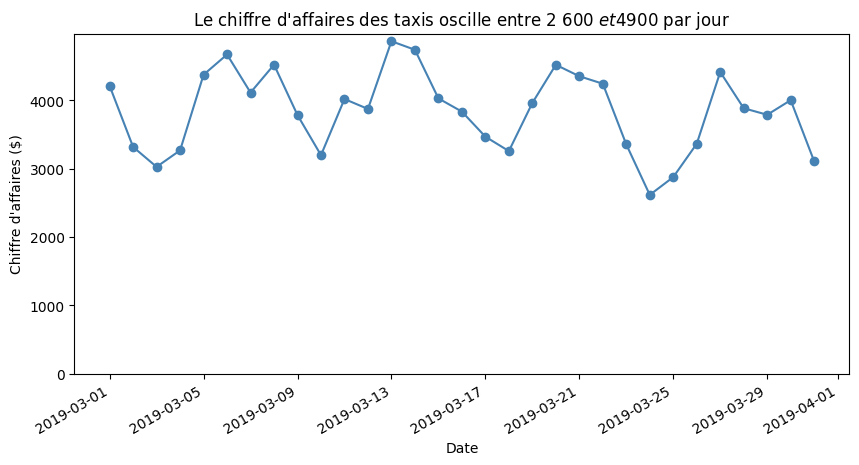

In [5]:
taxis["jour"] = taxis["pickup"].dt.date
ca_par_jour = taxis.groupby("jour")["total"].sum()
ca_par_jour = ca_par_jour[ca_par_jour > 500]

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(ca_par_jour.index, ca_par_jour.values, marker="o", color="steelblue")
ax.set_title("Le chiffre d'affaires des taxis oscille entre 2 600 $ et 4 900 $ par jour")
ax.set_xlabel("Date")
ax.set_ylabel("Chiffre d'affaires ($)")
ax.set_ylim(0, None)
fig.autofmt_xdate()
fig.savefig("figures/04_taxis_ca_jour.png", dpi=150, bbox_inches="tight")
plt.show()

**Type** : courbe, car on suit une valeur dans le temps.

**Conclusion** : le chiffre d'affaires quotidien oscille entre 2 600 $ et 4 900 $ environ, sans tendance nette sur le mois. Le pic se situe vers le 13 mars et le creux vers le 24 mars. Un premier jour presque vide (début du jeu de données) a été écarté pour ne pas fausser la courbe.

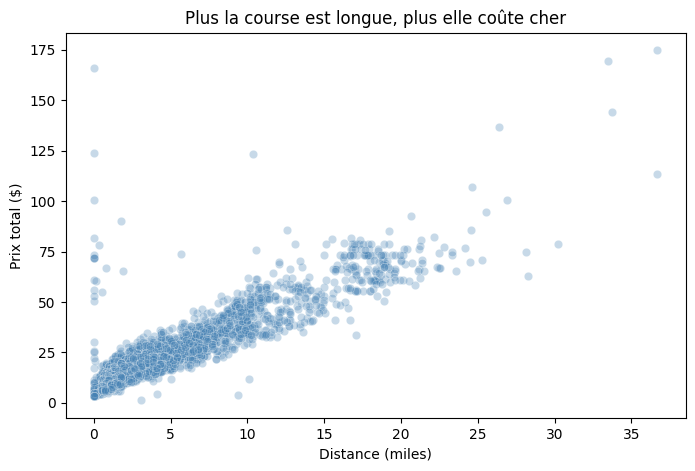

In [6]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.scatterplot(data=taxis, x="distance", y="total", alpha=0.3, color="steelblue", ax=ax)
ax.set_title("Plus la course est longue, plus elle coûte cher")
ax.set_xlabel("Distance (miles)")
ax.set_ylabel("Prix total ($)")
fig.savefig("figures/05_taxis_distance_prix.png", dpi=150, bbox_inches="tight")
plt.show()

**Type** : nuage de points, car on cherche le lien entre deux variables numériques.

**Conclusion** : le prix augmente de façon régulière avec la distance, avec quelques courses plus chères que ce que leur distance laisse prévoir.